# Experiências de Soft Labels — Exp. 1 a Exp. 7

Resultados da versão ponderada pelo fit. Exp. 6 corresponde à confirmação A/B; Exp. 7, à comparação das mensagens com MC Dropout. Os modelos locais e o modelo global são avaliados separadamente nos holdouts dos próprios clientes. Os resultados são exploratórios; test reservado.

In [ ]:
from pathlib import Path
import sys
root=Path.cwd().resolve()
while not (root/'requirements.txt').exists() and root!=root.parent: root=root.parent
sys.path.insert(0,str(root))

## Exp. 1 — Avaliação separada por dataset

In [1]:
from support.softlabels_overview import render_experiment
render_experiment(1)

Cinco arquiteturas em cada dataset, em federações separadas: dez configurações, seed 2026. Cada resultado desta secção refere-se apenas à sua origem.

PR-AUC local: modelo do cliente no seu próprio holdout. Global: modelo global nos mesmos holdouts. Pesos proporcionais ao fit; não se juntam previsões numa curva única.

Configuração,PR-AUC local,Desvio local,PR-AUC global,Desvio global,Seeds,Cobertura AP
Icentia: CNN+BiLSTM,0.6436,NaN,0.1519,NaN,1,1.0
PhysioNet: CNN+BiLSTM,0.5564,NaN,0.6539,NaN,1,1.0
PhysioNet: ResNet34,0.5371,NaN,0.5558,NaN,1,1.0
Icentia: AE+CNN,0.5097,NaN,0.1436,NaN,1,1.0
PhysioNet: AE+CNN,0.5086,NaN,0.6184,NaN,1,1.0
PhysioNet: MobileNetV2,0.4938,NaN,0.5454,NaN,1,1.0
Icentia: ResNet34,0.4604,NaN,0.1459,NaN,1,1.0
PhysioNet: CNN1D,0.4589,NaN,0.5793,NaN,1,1.0
Icentia: CNN1D,0.3742,NaN,0.1447,NaN,1,1.0
Icentia: MobileNetV2,0.2641,NaN,0.1494,NaN,1,1.0


Três rondas; uma época local por ronda. Amostra smoke fixa.

## Exp. 2 — Combinação dos melhores modelos

In [2]:
from support.softlabels_overview import render_experiment
render_experiment(2)

Cruzamento dos top 3 de cada dataset: nove configurações mistas, seed 2026.

PR-AUC local: modelo do cliente no seu próprio holdout. Global: modelo global nos mesmos holdouts. Pesos proporcionais ao fit; não se juntam previsões numa curva única.

Configuração,PR-AUC local,Desvio local,PR-AUC global,Desvio global,Seeds,Cobertura AP
IC: CNN+BiLSTM / PH: ResNet34,0.6115,NaN,0.5803,NaN,1,1.0
IC: CNN+BiLSTM / PH: MobileNetV2,0.5980,NaN,0.5803,NaN,1,1.0
IC: CNN+BiLSTM / PH: AE+CNN,0.5968,NaN,0.5858,NaN,1,1.0
IC: AE+CNN / PH: ResNet34,0.5202,NaN,0.5416,NaN,1,1.0
IC: AE+CNN / PH: AE+CNN,0.5136,NaN,0.5400,NaN,1,1.0
IC: AE+CNN / PH: MobileNetV2,0.5086,NaN,0.5413,NaN,1,1.0
IC: CNN1D / PH: ResNet34,0.4232,NaN,0.5456,NaN,1,1.0
IC: CNN1D / PH: AE+CNN,0.4160,NaN,0.5445,NaN,1,1.0
IC: CNN1D / PH: MobileNetV2,0.4101,NaN,0.5472,NaN,1,1.0


Três rondas; uma época local por ronda. Amostra smoke fixa.

## Exp. 3 — Exploração alargada de combinações

In [3]:
from support.softlabels_overview import render_experiment
render_experiment(3)

União das cinco arquiteturas atribuída às duas origens: 25 configurações, seeds 2026–2028.

PR-AUC local: modelo do cliente no seu próprio holdout. Global: modelo global nos mesmos holdouts. Pesos proporcionais ao fit; não se juntam previsões numa curva única.

Configuração,PR-AUC local,Desvio local,PR-AUC global,Desvio global,Seeds,Cobertura AP
IC: AE+CNN / PH: MobileNetV2,0.6009,0.0822,0.4786,0.0780,3,1.0
IC: AE+CNN / PH: ResNet34,0.5926,0.0686,0.4743,0.0764,3,1.0
IC: CNN+BiLSTM / PH: MobileNetV2,0.5866,0.0252,0.4774,0.0901,3,1.0
IC: AE+CNN / PH: AE+CNN,0.5835,0.0688,0.4748,0.0719,3,1.0
IC: CNN+BiLSTM / PH: ResNet34,0.5759,0.0320,0.4780,0.0898,3,1.0
IC: CNN+BiLSTM / PH: AE+CNN,0.5686,0.0260,0.4719,0.0987,3,1.0
IC: AE+CNN / PH: CNN+BiLSTM,0.5660,0.0526,0.4731,0.0780,3,1.0
IC: AE+CNN / PH: CNN1D,0.5639,0.0676,0.4724,0.0781,3,1.0
IC: CNN+BiLSTM / PH: CNN+BiLSTM,0.5525,0.0566,0.4707,0.0936,3,1.0
IC: CNN+BiLSTM / PH: CNN1D,0.5495,0.0342,0.4701,0.0974,3,1.0


Três rondas; uma época local por ronda. Amostra smoke fixa.

## Exp. 4 — Escolha da arquitetura por cliente

In [4]:
from support.softlabels_overview import render_experiment
render_experiment(4)

Três regras de escolha: modelo comum, por dataset ou por cliente. Amostra ampliada, seleção interna sem holdout/dev; seeds 2026–2030.

PR-AUC local: modelo do cliente no seu próprio holdout. Global: modelo global nos mesmos holdouts. Pesos proporcionais ao fit; não se juntam previsões numa curva única.

Configuração,PR-AUC local,Desvio local,PR-AUC global,Desvio global,Seeds,Cobertura AP
Modelo por cliente,0.6055,0.1187,0.4660,0.0756,5,1.0
Modelo comum,0.6009,0.1031,0.4641,0.0679,5,1.0
Modelo por dataset,0.5943,0.1099,0.4722,0.0751,5,1.0


Três rondas; uma época local por ronda. Na Exp. 4, a seleção interna dos candidatos usa três épocas e a avaliação final usa fit+seleção.

## Exp. 5 — Melhores combinações e referências homogéneas

In [5]:
from support.softlabels_overview import render_experiment
render_experiment(5)

Análise focada de nove cruzamentos top 3 × top 3 e quatro referências homogéneas adicionais, 13 configurações, seeds 2026–2028. Subconjunto da grelha da Exp. 3, sem validação independente.

PR-AUC local: modelo do cliente no seu próprio holdout. Global: modelo global nos mesmos holdouts. Pesos proporcionais ao fit; não se juntam previsões numa curva única.

Configuração,PR-AUC local,Desvio local,PR-AUC global,Desvio global,Seeds,Cobertura AP
IC: AE+CNN / PH: MobileNetV2,0.6009,0.0822,0.4786,0.0780,3,1.0
IC: AE+CNN / PH: ResNet34,0.5926,0.0686,0.4743,0.0764,3,1.0
IC: CNN+BiLSTM / PH: MobileNetV2,0.5866,0.0252,0.4774,0.0901,3,1.0
IC: AE+CNN / PH: AE+CNN,0.5835,0.0688,0.4748,0.0719,3,1.0
IC: CNN+BiLSTM / PH: ResNet34,0.5759,0.0320,0.4780,0.0898,3,1.0
IC: CNN+BiLSTM / PH: AE+CNN,0.5686,0.0260,0.4719,0.0987,3,1.0
IC: CNN+BiLSTM / PH: CNN+BiLSTM,0.5525,0.0566,0.4707,0.0936,3,1.0
IC: CNN1D / PH: MobileNetV2,0.4785,0.0708,0.4718,0.0804,3,1.0
IC: CNN1D / PH: ResNet34,0.4679,0.0464,0.4723,0.0789,3,1.0
IC: CNN1D / PH: AE+CNN,0.4598,0.0448,0.4661,0.0804,3,1.0


Três rondas; uma época local por ronda. Amostra smoke fixa.

## Exp. 6 — Comparação final A/B

In [6]:
from support.softlabels_overview import render_experiment
render_experiment(6)

A: AE+CNN no Icentia e MobileNetV2 no PhysioNet. B: CNN1D no Icentia e MobileNetV2 no PhysioNet. Amostra ampliada, dez épocas locais por ronda, seeds 2031–2035. Fonte: versão ponderada validada; os artefactos históricos 50/50 não são usados.

PR-AUC local: modelo do cliente no seu próprio holdout. Global: modelo global nos mesmos holdouts. Pesos proporcionais ao fit; não se juntam previsões numa curva única.

Configuração,PR-AUC local,Desvio local,PR-AUC global,Desvio global,Seeds,Cobertura AP
A: AE+CNN / MobileNetV2,0.8048,0.0185,0.438,0.0782,5,1.0
B: CNN1D / MobileNetV2,0.7671,0.0080,0.456,0.0894,5,1.0


**Escolha da Exp. 6: A: AE+CNN / MobileNetV2.** Critério: maior AP local ponderada pelo fit nas cinco seeds. Os resultados históricos com pesos 50/50 não sustentam esta escolha.

## Exp. 7 — Representação das mensagens e MC Dropout

Quatro representações: 64 probabilidades, 32 probabilidades de anomalia, 32 médias MC e 32 médias + 32 std MC. Vinte passagens MC Dropout por âncora, candidata A, dez épocas locais por ronda, seeds 2031–2035. Comparação sem SA/LDP; mantém-se a identidade da âncora e da classe anomalia.

PR-AUC local: modelo do cliente no seu próprio holdout. Global: modelo global nos mesmos holdouts. Pesos proporcionais ao fit; não se juntam previsões numa curva única.

## Nova experiência — média e desvio-padrão por âncora com MC Dropout

A proposta escolhida envia uma média e um desvio-padrão **por âncora**, calculados sobre 20 previsões estocásticas da **probabilidade de anomalia da mesma âncora**. A média continua associada à classe anomalia; `p(normal) = 1 − média`. O desvio-padrão mede variabilidade das previsões, não é calculado entre as duas classes nem entre âncoras diferentes. A opção anterior de dois números por cliente foi interrompida e preservada em `artifacts/softlabels_moments_history/client_wide_v1/`; não é misturada nesta experiência.

| Representação por cliente/ronda | Números float32 | Payload sem contagem de fit | Objetivo |
|---|---:|---:|---|
| Atual: normal e anomalia por âncora | 64 | 256 B | Referência determinística |
| Só anomalia por âncora | 32 | 128 B | Eliminar redundância binária |
| MC Dropout: só média de anomalia por âncora | 32 | 128 B | Isolar o efeito de repetir previsões |
| MC Dropout: média e std de anomalia por âncora | 64 | 256 B | Usar também a variabilidade na aprendizagem |

**Exemplo:** previsões de anomalia `[0,80; 0,85; 0,90]` na mesma âncora dão média 0,85 e std aproximadamente 0,041. O servidor associa essa âncora a `[normal=0,15; anomalia=0,85]`, mantendo a informação de classe. Isto não garante a mesma decisão de uma única previsão determinística; usa a previsão média. Também não se preserva toda a distribuição com apenas dois momentos.

**MC Dropout:** o professor faz 20 passagens com as camadas Dropout ativas. As restantes camadas, incluindo BatchNorm, permanecem em avaliação; as âncoras não atualizam as suas estatísticas. O estado do gerador aleatório é restaurado após as passagens, e as duas variantes MC usam as mesmas sementes de amostragem. O aumento de cálculo é contabilizado. [Fundamento de MC Dropout — Gal e Ghahramani, 2016](https://proceedings.mlr.press/v48/gal16.html).

**Agregação por âncora:** `mu = sum(w_i*mu_i)` e `var = sum(w_i*(sigma_i²+mu_i²)) − mu²`. Esta variância da mistura inclui a variabilidade dentro de cada professor e o desacordo entre professores. Não é a variância estatística da média do ensemble, nem uma medida de confiança calibrada.

**Uso do std no aluno:** a média fornece o alvo suave `[1−mu, mu]`. Na variante média+std, a entropia cruzada de cada âncora é ponderada por `1/(1+4*var)`, normalizada para média 1 entre as 32 âncoras. A constante 4 vem do limite de variância 1/4 de uma probabilidade em [0,1]; a regra é fixada antes de avaliar os resultados, sem ajustar ao holdout. A variante só com médias MC usa a mesma entropia cruzada sem essa ponderação, permitindo separar o efeito das previsões repetidas do efeito do std.

**Desenho e critérios:** candidata A (AE+CNN no Icentia e MobileNetV2 no PhysioNet), CNN1D global, mesmos dados agrupados, cinco seeds 2031–2035, três rondas e dez épocas locais. Pesos de fit 72,73%/27,27%. PR-AUC local no holdout do próprio cliente é principal; PR-AUC global nos mesmos holdouts é secundário. Usa-se a última ronda fixa, médias ponderadas e diferenças pareadas. Dev é secundário, test reservado e holdout exploratório. As referências concluídas só são reutilizadas quando compatíveis e novamente validadas.

Esta ablação é **sem SA/LDP**, para isolar a representação. Para uma futura SA, os clientes poderiam preparar momentos aditivos (`mu` e `sigma²+mu²`) em vez de somar desvios-padrão diretamente. Média+std por âncora mantém os mesmos 64 valores da referência, logo não se presume poupança de bytes; a vantagem potencial é informação sobre variabilidade. Nenhuma variante demonstra maior privacidade ou menor consumo energético apenas pelo formato da mensagem. O download da CNN1D global é mantido e contabilizado nas quatro variantes.


{'status': 'complete', 'validated_conditions': 20, 'reused_baselines': 5, 'signature': 'ce19a4b15f1274b85aa469868ed01580d9def9b65dd9ca23014b825799b65973'}

**20/20 condições completas e validadas.** `n` mostra as seeds realmente disponíveis; resultados incompletos não permitem uma decisão final.

{'representation': 'anomaly32', 'status': 'running', 'kind': 'Softlabels', 'condition': 'plain', 'seed': 2035, 'round': 3, 'signature': 'ce19a4b15f1274b85aa469868ed01580d9def9b65dd9ca23014b825799b65973'}

{'representation': 'mc_mean32', 'status': 'running', 'kind': 'Softlabels', 'condition': 'plain', 'seed': 2035, 'round': 3, 'signature': 'ce19a4b15f1274b85aa469868ed01580d9def9b65dd9ca23014b825799b65973'}

{'representation': 'mc_meanstd64', 'status': 'running', 'kind': 'Softlabels', 'condition': 'plain', 'seed': 2035, 'round': 3, 'signature': 'ce19a4b15f1274b85aa469868ed01580d9def9b65dd9ca23014b825799b65973'}

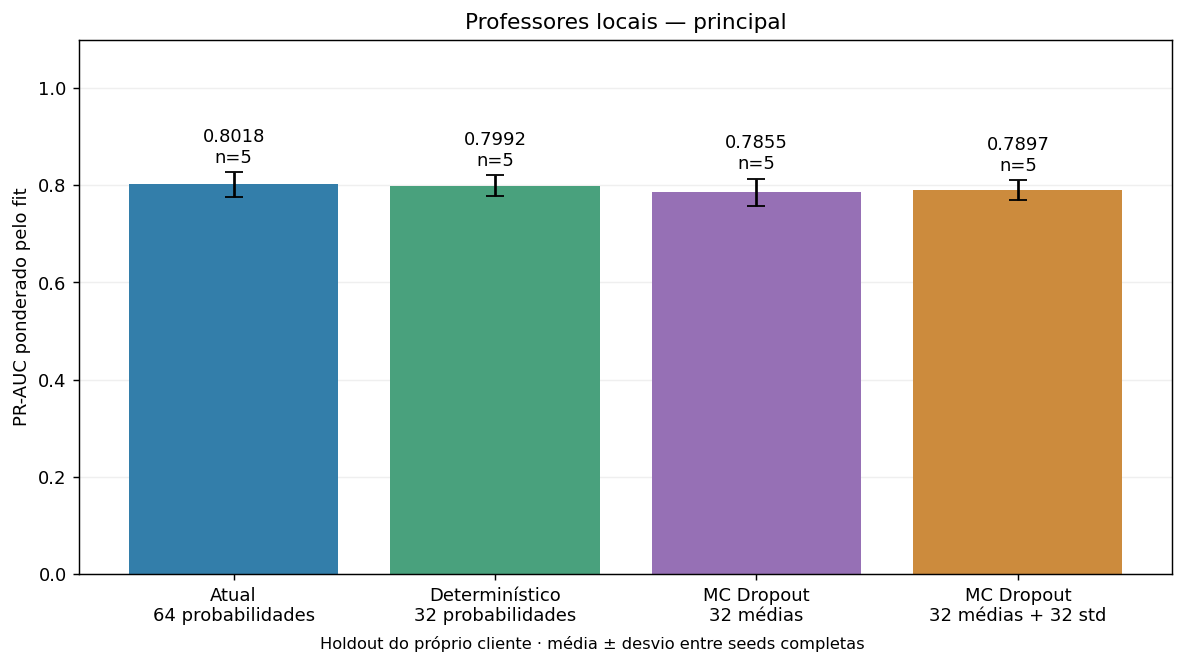

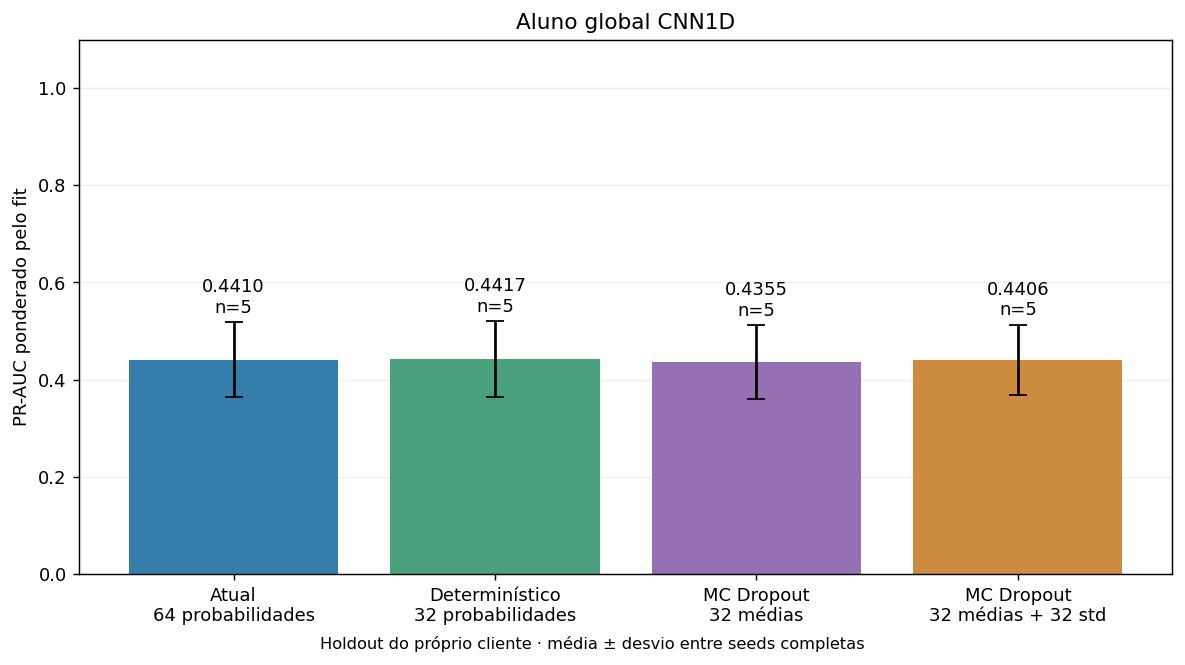

mode,seed,role,pr_auc_ap,valid_clients,total_clients,fit_coverage
probabilities64,2031,global,0.452283,22,22,1.0
probabilities64,2031,local,0.788336,22,22,1.0
probabilities64,2032,global,0.504633,22,22,1.0
probabilities64,2032,local,0.788149,22,22,1.0
probabilities64,2033,global,0.309112,22,22,1.0
probabilities64,2033,local,0.844688,22,22,1.0
probabilities64,2034,global,0.485029,22,22,1.0
probabilities64,2034,local,0.782420,22,22,1.0
probabilities64,2035,global,0.453975,22,22,1.0
probabilities64,2035,local,0.805574,22,22,1.0


### Comunicação média por cliente no ciclo de três rondas — KiB

upload_bytes,download_bytes,total_bytes
0.761719,318.828125,319.589844
0.386719,318.828125,319.214844
0.386719,318.828125,319.214844
0.761719,318.828125,319.589844


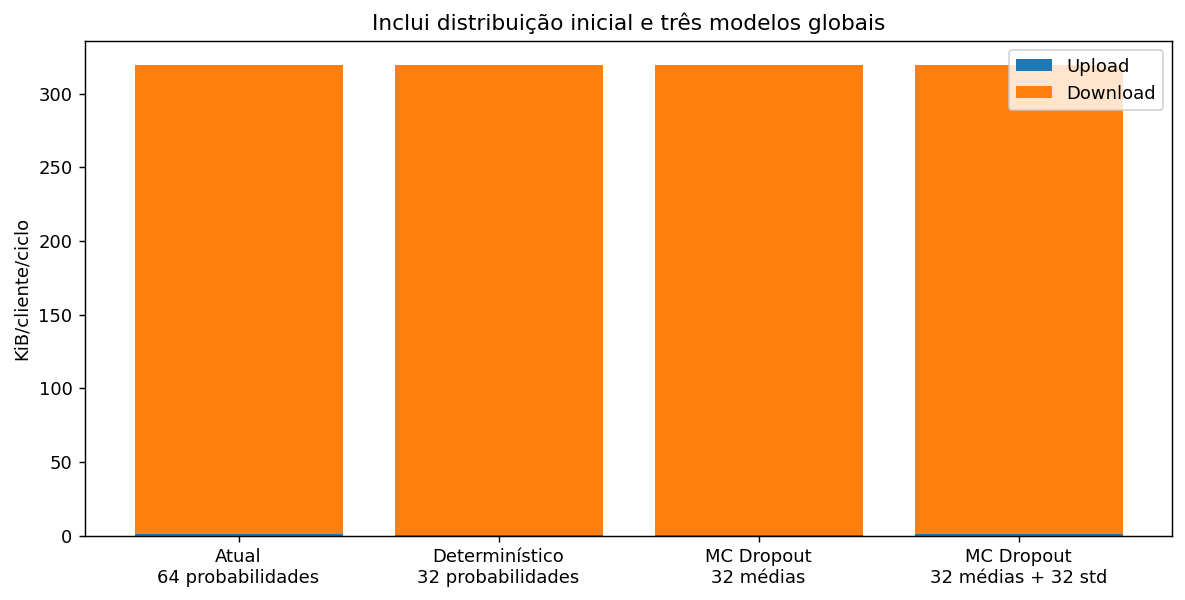

mode,seed,role,delta_vs_current
anomaly32,2031,global,0.007352
anomaly32,2031,local,0.000887
anomaly32,2032,global,-0.003082
anomaly32,2032,local,-0.006583
anomaly32,2033,global,-0.001850
anomaly32,2033,local,-0.007842
anomaly32,2034,global,0.008382
anomaly32,2034,local,0.011239
anomaly32,2035,global,-0.007468
anomaly32,2035,local,-0.010695


### Comparação concluída

As quatro representações foram avaliadas nas mesmas cinco seeds. A leitura principal é o PR-AUC local e a diferença pareada; o PR-AUC global e os bytes mostram o compromisso. A variante MC média+std mantém a identidade das âncoras e usa o mesmo payload de 64 valores da referência. A variante de 32 valores reduz o payload em 50% com equivalência matemática binária; não se deve atribuir significado estatístico a pequenas diferenças numéricas sem análise adicional.

role,global,local
,0.441673,0.799234
,0.435518,0.785467
,0.440621,0.789740
,0.441006,0.801833


In [7]:
from support.softlabels_overview import render_experiment
render_experiment(7)

## Comparisons — comparação entre experiências

A configuração de cada ponto é escolhida pelo **maior PR-AUC local ponderado, em média entre seeds**. O PR-AUC global apresentado pertence à mesma configuração. A escolha é exploratória e pode beneficiar da seleção entre várias alternativas. Na Exp. 1, escolhe-se uma arquitetura por origem e combina-se a AP por pesos de fit; são duas federações separadas. Na Exp. 7 usam-se apenas as seeds já concluídas nas quatro variantes, evitando escolher uma variante a partir de seeds diferentes.

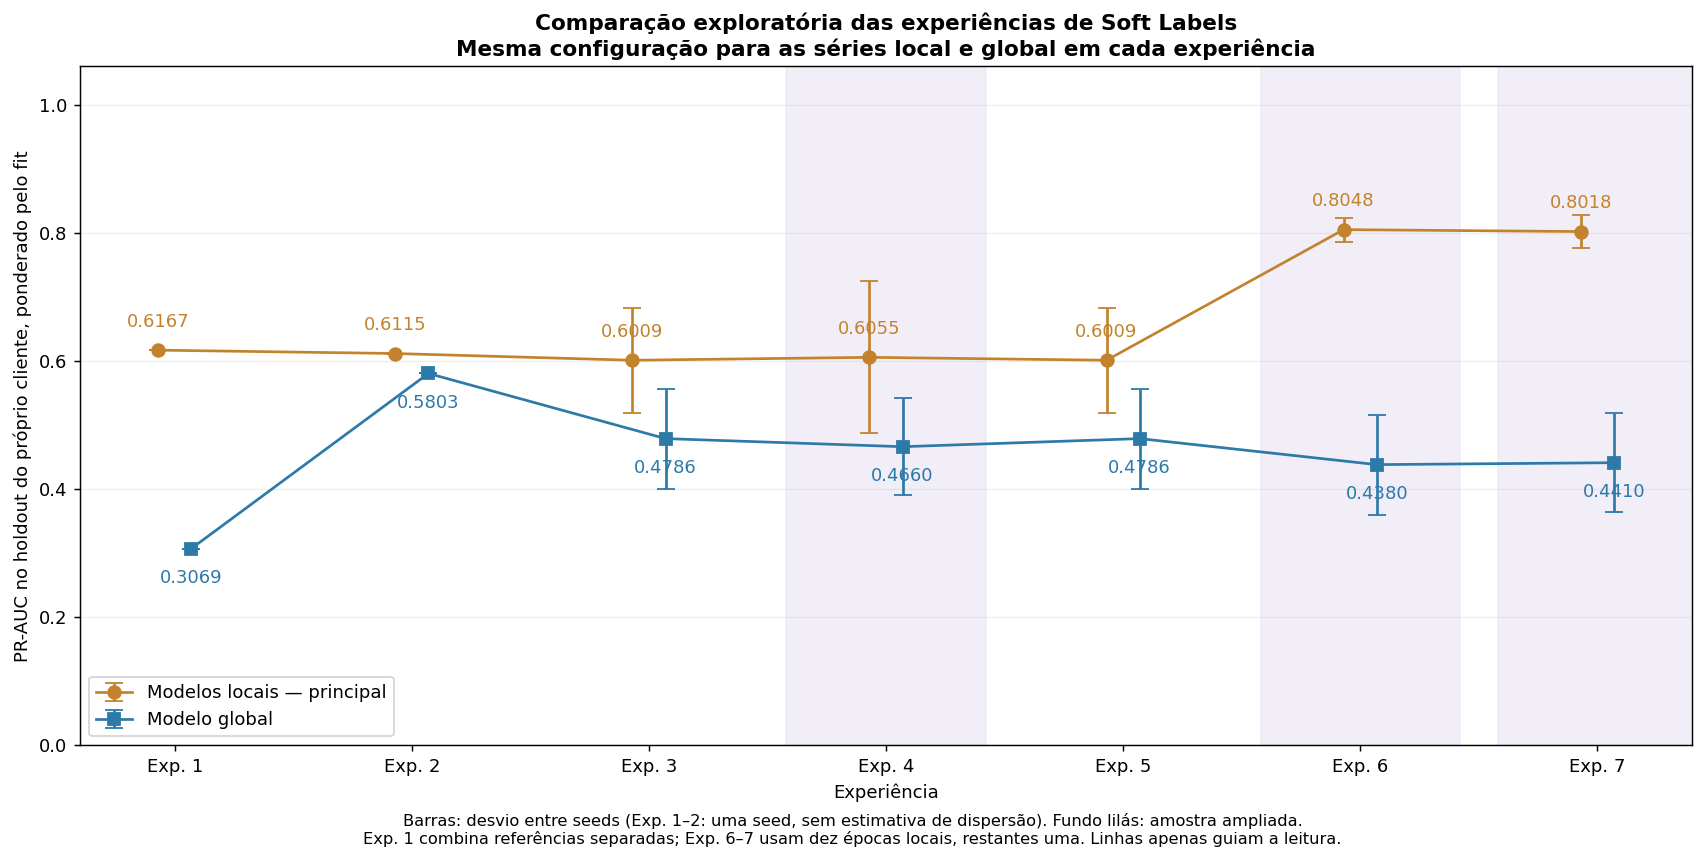

Experiência,Configuração selecionada,PR-AUC local,PR-AUC global,Seeds,Amostra,Épocas locais/ronda,Parcial
1,Icentia: CNN+BiLSTM + PhysioNet: CNN+BiLSTM,0.6167,0.3069,1,smoke,1,False
2,IC: CNN+BiLSTM / PH: ResNet34,0.6115,0.5803,1,smoke,1,False
3,IC: AE+CNN / PH: MobileNetV2,0.6009,0.4786,3,smoke,1,False
4,Modelo por cliente,0.6055,0.4660,5,ampliada,1,False
5,IC: AE+CNN / PH: MobileNetV2,0.6009,0.4786,3,smoke,1,False
6,A: AE+CNN / MobileNetV2,0.8048,0.4380,5,ampliada,10,False
7,64 probabilidades,0.8018,0.4410,5,ampliada,10,False


**Maior média local observada neste gráfico: Exp. 6, A: AE+CNN / MobileNetV2 (0.8048).** É uma descrição dos resultados disponíveis, não uma prova de superioridade: as amostras, épocas, seeds e número de configurações exploradas diferem. A Exp. 5 reutiliza o espaço de configurações da Exp. 3. Para escolher a representação das mensagens, a comparação controlada relevante é entre as quatro variantes da Exp. 7, nos mesmos dados e seeds. A escolha deve considerar também comunicação e cálculo; test continua reservado.

### Combinação recomendada

**Para maximizar o PR-AUC local, recomenda-se a configuração A: AE+CNN nos clientes Icentia11k, MobileNetV2 nos clientes PhysioNet 2017 e CNN1D como modelo global, mantendo as probabilidades determinísticas por âncora.** A configuração A foi selecionada na Exp. 6 pelo PR-AUC local ponderado nas cinco seeds. Na Exp. 7, a representação atual de 64 probabilidades teve a maior média local (0.8018), com PR-AUC global de 0.4410. As variantes MC Dropout, com ou sem std, não melhoraram a média local nesta experiência e acrescentaram custo de cálculo; não são a primeira opção para prosseguir.

**Para wearables com prioridade à comunicação, a alternativa é a mesma configuração A enviando só 32 probabilidades de anomalia**, com PR-AUC local de 0.7992 e global de 0.4417. A diferença local observada face aos 64 valores é 0.0026 (0.26 pontos percentuais). Esta alternativa reduz o payload de probabilidades em 50% e permite reconstruir a probabilidade normal por `1 − p(anomalia)`. O download do modelo global e as mensagens adicionais de um eventual protocolo SA não são reduzidos nessa proporção. A equivalência é matemática; as pequenas diferenças medidas podem resultar de arredondamentos e da sua propagação entre rondas, não demonstrando superioridade estatística de uma codificação.

**Decisão:** manter A e a distilação determinística; usar 64 valores quando a prioridade estrita é a maior média local observada, ou 32 valores quando se privilegia o compromisso com a comunicação em wearables. Esta escolha é exploratória e não demonstra maior privacidade, menor consumo energético ou desempenho em novos pacientes. A validade das âncoras sintéticas e a generalização do modelo global continuam a exigir avaliação; o conjunto de teste permanece reservado.

In [8]:
from support.softlabels_overview import render_comparisons
render_comparisons()